## Setup & load 

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('online_retail_II.csv')

In [3]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


## Audit  

In [5]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df = df.rename(columns={'Customer ID': 'customer_id'})

In [6]:
raw=df.copy()
raw_rows = len(df)
print(df.shape)

(1067371, 8)


In [7]:
print('missing Description :', df['Description'].isna().sum())
print('missing customer_id :', df['customer_id'].isna().sum())

missing Description : 4382
missing customer_id : 243007


In [8]:
len(df[df['Invoice'].str.startswith('C')])

19494

In [9]:
len(df[df['customer_id'].isna() & df['Invoice'].str.startswith('C')])

750

750 no-ID rows are cancellations; the other ~242,257 no-ID rows are ordinary sales that cannot be attributed to a customer.

In [10]:
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
customer_id    243007
Country             0
dtype: int64

In [11]:
df.isna().mean()*100

Invoice         0.000000
StockCode       0.000000
Description     0.410541
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
customer_id    22.766873
Country         0.000000
dtype: float64

In [12]:
g = df.groupby('Invoice')['customer_id']
print(((g.count() > 0) & (g.count() < g.size())).sum())   # invoices with BOTH missing and present IDs

0


In [13]:
len(df[df['Description'].isna()])

4382

In [14]:
len(df[(df['Description'].isna())&(df['customer_id'].isna())])

4382

In [15]:
len(df[(df['Description'].isna())&(df['customer_id'].isna())&(df['Price']==0.0)])

4382

That means the missing '4382' description's have a price '0'and they donot have any customer_id; they are supposed tobe dropped then.

In [16]:
len(df[(df['Quantity']==0)])

0

In [17]:
len(df[(df['Quantity']<0)])

22950

In [18]:
len(df[(df['Quantity']<0) & (df['Invoice'].str.startswith('C'))])

19493

In [19]:
df[(df['Quantity']<0) & (~df['Invoice'].str.startswith('C'))].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [20]:
df[(df['Quantity']<0) & (~df['Invoice'].str.startswith('C'))&(df['Price']==0)].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [21]:
df[(df['Quantity']<0) & (~df['Invoice'].str.startswith('C'))&(df['Price']==0)& (df['customer_id'].isna())].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


All those with Quantity<0 and not having a cancelled invoice have a price of '0' and cusid =null; we can drop these rows 

In [22]:
df[(df['Price']<0)].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [23]:
len(df[(df['Price']==0)])

6202

In [24]:
len(df[(df['Price']==0)&(~df['customer_id'].isna())])

71

In [25]:
z = df[(df['Price'] == 0) & df['customer_id'].notna()]
print(len(z), z.duplicated().sum(), z['Invoice'].str.startswith('C').sum())

71 1 0


Price matters: Spent = Price x Quantity drives every revenue metric. Only rows with Price <= 0 are excluded, because they carry no revenue.

In [26]:
len(df[df.duplicated()])

34335

In [27]:
len(df[df.duplicated(keep=False)].sort_values(['Invoice','StockCode']))

67242

Here we can see that the duplicate rows count up to 34k, they need tobe removed

Chk stockcodes , whether they are reg 5 nums,5nums a digit or something else

In [28]:
print(
"The max price is :" , df['Price'].max(),
"\nThe min price is :" ,  df['Price'].min(),
"\nThe max quantity is :",df['Quantity'].max(),
"\nThe min quantity is :",df['Quantity'].min() )

The max price is : 38970.0 
The min price is : -53594.36 
The max quantity is : 80995 
The min quantity is : -80995


In [29]:
df[df['Price']==df['Price'].max()]


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.0,15098.0,United Kingdom


In [30]:
df[df['Price']==df['Price'].min() ]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom


In [31]:
df[df['Quantity']==df['Quantity'].max()  ]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [32]:
df[df['Quantity']==df['Quantity'].min()  ]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


Well the positive and negative metrics are the exact same , so we know that the exact same item is purchased and then cancelled 
We can now adjust them in diff tables ; -ve in returns and +ve in purchases 

In [33]:
print(
    "The min invoice date is :" , df['InvoiceDate'].min(),
   "\nThe max invoice date is :" , df['InvoiceDate'].max()
)

The min invoice date is : 2009-12-01 07:45:00 
The max invoice date is : 2011-12-09 12:50:00


## Findings
previously i have seen that the customerid as na is which acc about 243,007 (22.8%) rows is the biggest ;
excat duplicated rows are about 34K and need tobe removed;Stk codes are having a lot of variety, difficult to deal with;
the returns / cancellations account for about 19k and only 750 of them are the ones with no cusid;
the quantity below zero and cancellations acc for about  19k rows;other 3K+ quantity<0 have no cusid and they generate no value , they should be removed;
prices below below or eual to zero have no significance as they donot have cusid (except for 71 rows, could be ignored or needed tobe mapped according to stkcode and retrieved) 

## Cleaning (row-count waterfall/log)

In [34]:
#this is a list of dictionaries that will hold the information about each step in the data cleaning process!
log = []

def log_step(step, before, after, why):
    log.append({'step': step, 'rows_before': before, 'rows_after': after,
                      'removed': before - after, 'why': why})

In [35]:
before = len(df)
df = df.drop_duplicates()
log_step('drop exact duplicates', before, len(df),
         'identical in every column; first copy kept')

In [36]:
before = len(df)
nocus_df = df[df['customer_id'].isna()].copy()   # set aside for the Section 8 decision
df = df.dropna(subset=['customer_id'])
log_step('drop missing customer_id', before, len(df),
         'cannot be attributed to a customer; set aside in nocus_df')

In [37]:
before = len(df)
is_cancel = df['Invoice'].str.startswith('C')
returns_df = df[is_cancel].copy()
df = df[~is_cancel]
log_step('split off cancellations (Invoice starts with C)', before, len(df),
         'kept in returns_df, not deleted')

In [38]:
len(df[df['Quantity']<0])
#checking that the prev queries have worked

0

In [39]:
before = len(df)
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]
log_step('drop Quantity<=0 or Price<=0', before, len(df),
         'Price = 0 rows add no revenue and are not sales; the Quantity condition removed nothing after cancellations were split')

In [40]:
before = len(df)
is_product = df['StockCode'].str.fullmatch(r'\d{5}[A-Za-z]*')   # True/False per row
non_product_df = df[~is_product].copy()
df = df[is_product]
log_step('split off non-product StockCodes', before, len(df),
         'kept in non_product_df, not deleted')

In [41]:
non_product_df.groupby('StockCode')['Description'].first()

StockCode
ADJUST          Adjustment by john on 26/01/2010 16
ADJUST2         Adjustment by Peter on Jun 25 2010 
BANK CHARGES                           Bank Charges
C2                                         CARRIAGE
D                                          Discount
DOT                                  DOTCOM POSTAGE
M                                            Manual
PADS                     PADS TO MATCH ALL CUSHIONS
POST                                        POSTAGE
SP1002                       KID'S CHALKBOARD/EASEL
TEST001                     This is a test product.
TEST002                     This is a test product.
Name: Description, dtype: str

In [42]:
assert len(non_product_df) + len(df) == before     # nothing lost or double-counted
print(len(df), len(non_product_df))                # df should keep the large majority
non_product_df['StockCode'].value_counts().head(15)   # should look like POST, M, AMAZONFEE...

776577 2848


StockCode
POST            1803
M                681
C2               248
ADJUST            32
BANK CHARGES      31
PADS              17
DOT               16
TEST001            9
D                  5
ADJUST2            3
SP1002             2
TEST002            1
Name: count, dtype: int64

In [43]:
sales_df = df.copy()                                   
sales_df['customer_id'] = sales_df['customer_id'].astype('int64')   
sales_df['Spent'] = sales_df['Price'] * sales_df['Quantity']

In [44]:
sales_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country,Spent
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [45]:
returns_df['returned_amt'] = returns_df['Price'] * -returns_df['Quantity']

In [46]:
returns_df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country,returned_amt
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,17.00
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,12.60
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,35.40
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,15.00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,15.00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,20.40
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,35.40
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,12.75


In [47]:
pd.DataFrame(log)

,step,rows_before,rows_after,removed,why
0,drop exact duplicates,1067371,1033036,34335,identical in every column; first copy kept
1,drop missing customer_id,1033036,797885,235151,cannot be attributed to a customer; set aside ...
2,split off cancellations (Invoice starts with C),797885,779495,18390,"kept in returns_df, not deleted"
3,drop Quantity<=0 or Price<=0,779495,779425,70,Price = 0 rows add no revenue and are not sale...
4,split off non-product StockCodes,779425,776577,2848,"kept in non_product_df, not deleted"


In [48]:
#to print the total removed as a sum below all removed values in the table
#convert the total_removed to a int 
total_removed = int(pd.DataFrame(log)['removed'].sum())
total_removed


290794

In [49]:
assert raw_rows - total_removed == len(sales_df)

In [50]:
conn = sqlite3.connect('Retail_analysis.db')
sales_df.to_sql('transactions', conn, if_exists='replace', index=False)

776577

In [51]:
#Sanity Chk
Query=""" 
SELECT count(*) as Total_rows
    FROM transactions;
"""
result= pd.read_sql_query(Query, conn)
result

,Total_rows
0,776577


In [52]:
assert result.iloc[0]['Total_rows']==len(sales_df)

In [53]:
#chking invoicedate in transactions table
Query="""
    select Invoicedate,customer_id
    from transactions
    order by Invoicedate Asc limit 10;
"""
result=pd.read_sql_query(Query,conn)
result

,InvoiceDate,customer_id
0,2009-12-01 07:45:00,13085
1,2009-12-01 07:45:00,13085
2,2009-12-01 07:45:00,13085
3,2009-12-01 07:45:00,13085
4,2009-12-01 07:45:00,13085
5,2009-12-01 07:45:00,13085
6,2009-12-01 07:45:00,13085
7,2009-12-01 07:45:00,13085
8,2009-12-01 07:46:00,13085
9,2009-12-01 07:46:00,13085


In [54]:
n_before = len(returns_df)
returns_df = returns_df[returns_df['StockCode'].str.fullmatch(r'\d{5}[A-Za-z]*')].copy()
print('non-product cancellation lines excluded:', n_before - len(returns_df))
returns_df['customer_id'] = returns_df['customer_id'].astype('int64')
returns_df['returned_amt'] = returns_df['Price'] * -returns_df['Quantity']

non-product cancellation lines excluded: 804


In [55]:
returns_df.to_sql('returns', conn, if_exists='replace', index=False)

17586

In [56]:
non_product_df.to_sql('non_product', conn, if_exists='replace', index=False)

2848

## SQLite and per-customer metrics

In [57]:
Query = """
    SELECT customer_id,
           SUM(Spent)                           AS total_spent,
           COUNT(DISTINCT Invoice)              AS order_freq,
           SUM(Spent) / COUNT(DISTINCT Invoice) AS avg_order_value
    FROM transactions
    GROUP BY customer_id
"""
customer_metrics=pd.read_sql_query(Query,conn)
customer_metrics

,customer_id,total_spent,order_freq,avg_order_value
0,12346,77352.96,3,25784.320000
1,12347,4921.53,8,615.191250
2,12348,1658.40,5,331.680000
3,12349,3678.69,3,1226.230000
4,12350,294.40,1,294.400000
...,...,...,...,...
5847,18283,2658.95,22,120.861364
5848,18284,411.68,1,411.680000
5849,18285,377.00,1,377.000000
5850,18286,1246.43,2,623.215000


## Sanity checks: SQL vs pandas

In [58]:
#sanity check for customer metrics table
assert customer_metrics.shape[0] == sales_df['customer_id'].nunique()
np.isclose(customer_metrics['total_spent'].sum(), sales_df['Spent'].sum())

np.True_

## Recency

In [59]:
#to calc the recency of a customer
# Query="""
#     select  
#             customer_id,
#             Max(InvoiceDate) as last_purchase_date
#     from transactions
#     group by customer_id
# """
# customer_last_buy=pd.read_sql_query(Query,conn)
# customer_metrics=customer_metrics.merge(customer_last_buy,on='customer_id',how='left')
# customer_metrics['recency'] = (pd.to_datetime(sales_df['InvoiceDate'].max()) - pd.to_datetime(customer_metrics['last_purchase_date'])).dt.days
# customer_metrics
recency_query = """
    SELECT customer_id, MAX(InvoiceDate) AS last_purchase_date
    FROM transactions
    GROUP BY customer_id
"""
last_purchase = pd.read_sql_query(recency_query, conn)
last_purchase['last_purchase_date'] = pd.to_datetime(last_purchase['last_purchase_date'])

customer_metrics = (customer_metrics.drop(columns=['last_purchase_date', 'recency_days'], errors='ignore')
                    .merge(last_purchase, on='customer_id', how='left'))

snapshot = raw['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)   # dataset's last day + 1
customer_metrics['recency_days'] = (snapshot - customer_metrics['last_purchase_date'].dt.normalize()).dt.days


Recency is measured from the dataset’s last day plus one, not today’s date.

In [60]:
# returns_query = """
#     SELECT customer_id,
#            COUNT(DISTINCT Invoice) AS return_count,
#            -SUM(Quantity * Price)  AS return_value
#     FROM returns
#     GROUP BY customer_id
# """
# returns_summary = pd.read_sql_query(returns_query, conn)

# customer_metrics = customer_metrics.merge(returns_summary, on='customer_id', how='left')
# customer_metrics[['return_count', 'return_value']] = customer_metrics[['return_count', 'return_value']].fillna(0)
# customer_metrics['return_count'] = customer_metrics['return_count'].astype(int)
# customer_metrics
# # chk: returners that don't exist in customer_metrics
# print((~returns_summary['customer_id'].isin(customer_metrics['customer_id'])).sum())
returns_query = """
    SELECT customer_id,
           COUNT(DISTINCT Invoice) AS return_count,
           -SUM(Quantity * Price)  AS return_value
    FROM returns
    GROUP BY customer_id
"""
returns_summary = pd.read_sql_query(returns_query, conn)

customer_metrics = (customer_metrics
    .drop(columns=['return_count', 'return_value', 'net_spent'], errors='ignore')
    .merge(returns_summary, on='customer_id', how='left'))
customer_metrics[['return_count', 'return_value']] = customer_metrics[['return_count', 'return_value']].fillna(0)
customer_metrics['return_count'] = customer_metrics['return_count'].astype(int)
customer_metrics['net_spent'] = customer_metrics['total_spent'] - customer_metrics['return_value']

orphans = returns_summary[~returns_summary['customer_id'].isin(customer_metrics['customer_id'])]
print(len(orphans))      

23


In [61]:
customer_metrics[customer_metrics['customer_id'].isin([16446, 12346])][['customer_id', 'total_spent', 'return_value', 'net_spent']]

,customer_id,total_spent,return_value,net_spent
0,12346,77352.96,77183.6,169.36
4037,16446,168472.50,168469.6,2.90


In [62]:
returns_df[returns_df['customer_id'] == 12346]        # was the Jan 2011 order cancelled too?

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,customer_id,Country,returned_amt
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,77183.6


In [63]:
returns_df[returns_df['customer_id'].isin(orphans['customer_id'])]['InvoiceDate'].dt.to_period('M').value_counts().sort_index().head()

InvoiceDate
2009-12    58
2010-01     2
2010-03     9
2010-04     2
2010-05     2
Freq: M, Name: count, dtype: int64

In [64]:
customer_metrics['buyer_type'] = np.where(customer_metrics['order_freq'] > 1, 'repeat', 'one-time')

seg = customer_metrics.groupby('buyer_type').agg(
    customers=('customer_id', 'size'),
    revenue=('total_spent', 'sum'),
)
seg['pct_customers'] = (seg['customers'] / seg['customers'].sum() * 100).round(1)
seg['pct_revenue']   = (seg['revenue']   / seg['revenue'].sum()   * 100).round(1)
seg


,customers,revenue,pct_customers,pct_revenue
buyer_type,,,,
one-time,1618,555999.97,27.6,3.3
repeat,4234,16512568.00,72.4,96.7


In [65]:
customer_metrics['value_tier'] = pd.qcut(customer_metrics['total_spent'], q=4,
                                         labels=['Bronze', 'Silver', 'Gold', 'Platinum'])

tiers = customer_metrics.groupby('value_tier', observed=True).agg(
    customers=('customer_id', 'size'), min_spent=('total_spent', 'min'),
    max_spent=('total_spent', 'max'), revenue=('total_spent', 'sum'))
tiers['pct_revenue'] = (tiers['revenue'] / tiers['revenue'].sum() * 100).round(1)
tiers

,customers,min_spent,max_spent,revenue,pct_revenue
value_tier,,,,,
Bronze,1463,2.95,339.50,281260.01,1.6
Silver,1463,339.60,856.01,823052.66,4.8
Gold,1463,856.03,2240.90,2050837.94,12.0
Platinum,1463,2241.42,580987.04,13913417.36,81.5


In [66]:
invoices = sales_df.groupby('Invoice').agg(
    customer_id=('customer_id', 'first'), InvoiceDate=('InvoiceDate', 'first'),
    invoice_total=('Spent', 'sum'), n_lines=('StockCode', 'size'),
    max_qty=('Quantity', 'max')).reset_index()

## Outliers (IQR rule)

In [67]:
q1, q3 = invoices['invoice_total'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
invoices['is_outlier'] = invoices['invoice_total'] > upper_fence
print(q1, q3, upper_fence)

158.63 473.88 946.755


In [68]:
flagged = invoices[invoices['is_outlier']]
print(len(flagged), len(invoices), round(len(flagged) / len(invoices) * 100, 1))
print(round(flagged['invoice_total'].sum() / invoices['invoice_total'].sum() * 100, 1))

2861 36594 7.8
39.5


In [69]:
flagged.sort_values('invoice_total', ascending=False).head(10)               # biggest orders


,Invoice,customer_id,InvoiceDate,invoice_total,n_lines,max_qty,is_outlier
36561,581483,16446,2011-12-09 09:15:00,168469.60,1,80995,True
20095,541431,12346,2011-01-18 10:01:00,77183.60,1,74215,True
1587,493819,14156,2010-01-07 12:34:00,44051.60,94,624,True
26071,556444,15098,2011-06-10 15:28:00,38970.00,1,60,True
13228,524181,17450,2010-09-27 16:59:00,33167.80,13,760,True
30526,567423,17450,2011-09-20 11:05:00,31698.16,12,1944,True
14411,526934,18102,2010-10-14 09:46:00,26007.08,15,720,True
9877,515944,18102,2010-07-15 15:29:00,22863.36,17,300,True
26257,556917,12415,2011-06-15 13:37:00,22775.93,138,576,True
32545,572209,18102,2011-10-21 12:08:00,22206.00,7,300,True


In [70]:
flagged.groupby('customer_id').size().sort_values(ascending=False).head(10)  # who orders big, repeatedly


customer_id
18102    107
14646     89
14911     84
13694     71
14156     57
17511     49
15061     43
17450     41
13089     35
14298     34
dtype: int64

In [71]:
invoices.sort_values('max_qty', ascending=False).head(3)                     # is the 80,995 order flagged?

,Invoice,customer_id,InvoiceDate,invoice_total,n_lines,max_qty,is_outlier
36561,581483,16446,2011-12-09 09:15:00,168469.6,1,80995,True
20095,541431,12346,2011-01-18 10:01:00,77183.6,1,74215,True
2986,497946,13902,2010-02-15 11:57:00,16973.1,30,19152,True


## Monthly revenue trend

In [72]:
monthly = (sales_df.assign(month=sales_df['InvoiceDate'].dt.to_period('M'))
           .groupby('month', as_index=False)['Spent'].sum()
           .rename(columns={'Spent': 'revenue'}))
monthly.head()

,month,revenue
0,2009-12,677916.07
1,2010-01,533712.98
2,2010-02,497937.57
3,2010-03,665973.67
4,2010-04,585127.43


In [73]:
nocus_clean = nocus_df[~nocus_df['Invoice'].str.startswith('C')]
nocus_clean = nocus_clean[(nocus_clean['Quantity'] > 0) & (nocus_clean['Price'] > 0)
                        & nocus_clean['StockCode'].str.fullmatch(r'\d{5}[A-Za-z]*')]
nocus_clean = nocus_clean.assign(Spent=nocus_clean['Quantity'] * nocus_clean['Price'])

share = nocus_clean['Spent'].sum() / (nocus_clean['Spent'].sum() + sales_df['Spent'].sum()) * 100
print(f'{share:.1f}% of valid revenue has no customer_id')

# only if you decide to include them:
# monthly_all = (pd.concat([sales_df[['InvoiceDate', 'Spent']], nocus_clean[['InvoiceDate', 'Spent']]])
#                .assign(month=lambda d: d['InvoiceDate'].dt.to_period('M'))
#                .groupby('month', as_index=False)['Spent'].sum()
#                .rename(columns={'Spent': 'revenue'}))

13.1% of valid revenue has no customer_id


Decision: the chart uses customer-attributed revenue only; 13.1% of valid revenue has no customer ID

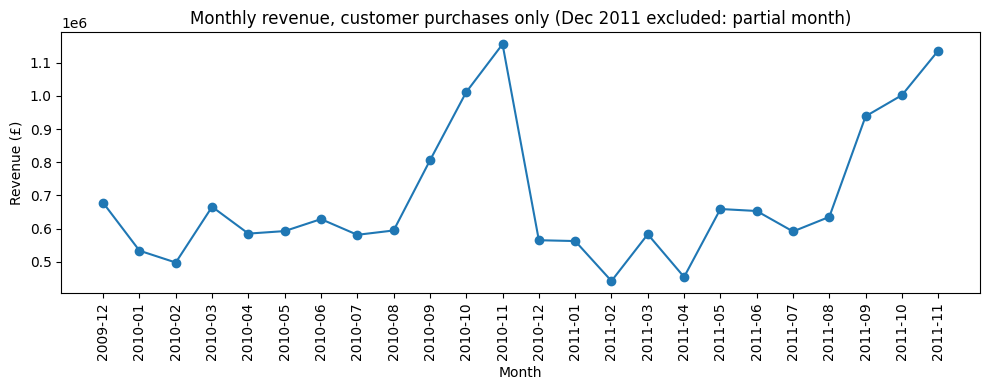

In [74]:
%matplotlib inline
plot_df = monthly[monthly['month'] < pd.Period('2011-12', 'M')]   # drop partial Dec 2011

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(plot_df['month'].astype(str), plot_df['revenue'], marker='o')
ax.set_title('Monthly revenue, customer purchases only (Dec 2011 excluded: partial month)')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (£)')
ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout()
plt.show()

In [75]:
monthly.sort_values('revenue', ascending=False).head(5)       # peak months

,month,revenue
11,2010-11,1155978.39
23,2011-11,1136534.00
10,2010-10,1011556.75
22,2011-10,1002326.56
21,2011-09,938752.63


In [76]:
(monthly.assign(year=monthly['month'].dt.year, mon=monthly['month'].dt.month)
        .pivot(index='mon', columns='year', values='revenue').round(0))   # same month, year over year

year,2009,2010,2011
mon,,,
1,NaN,533713.0,562683.0
2,NaN,497938.0,442294.0
3,NaN,665974.0,583144.0
4,NaN,585127.0,454441.0
5,NaN,592734.0,659242.0
6,NaN,628809.0,653265.0
7,NaN,581488.0,591604.0
8,NaN,594561.0,635514.0
9,NaN,805545.0,938753.0


In [78]:
import os
os.makedirs('outputs', exist_ok=True)

pd.DataFrame(log).to_csv('outputs/waterfall.csv', index=False)      
customer_metrics.to_csv('outputs/customer_metrics.csv', index=False)      # includes buyer_type and value_tier
monthly.to_csv('outputs/monthly_revenue.csv', index=False)
invoices[invoices['is_outlier']].to_csv('outputs/flagged_invoices.csv', index=False)

# reload one file to prove the export round-trips
print(pd.read_csv('outputs/customer_metrics.csv').shape, customer_metrics.shape)

(5852, 11) (5852, 11)
